# **Regression Practice Notebook**

This notebook contains practice questions for three regression techniques:
1. Simple Linear Regression
2. Multiple Linear Regression
3. Gradient Boosting Regressor

Each section uses a different dataset. Write your code in the empty cells below each question.

## **Section 1: Simple Linear Regression**

**Dataset:** `study_hours_exam_score.csv`
**Shape:** (1000, 2)
**Columns:** `StudyHours` (input), `ExamScore` (output)

**Q1.** Import the required libraries (`pandas`, `matplotlib.pyplot`) and load `study_hours_exam_score.csv` into a DataFrame. Display the first 5 rows.

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("C:/Users/raajm/Downloads/study_hours_exam_score.csv")
df

,StudyHours,ExamScore
0,5.59,56.64
1,8.92,74.03
2,1.00,25.87
3,4.33,48.35
4,2.61,25.43
...,...,...
995,11.72,99.36
996,4.43,44.04
997,8.36,76.02
998,4.59,57.01


**Q2.** Check the shape of the dataset and confirm there are no missing values.

In [4]:
print(df.shape)
print(df.isnull().sum())

(1000, 2)
StudyHours    0
ExamScore     0
dtype: int64


**Q3.** Create a scatter plot to visualize the relationship between `StudyHours` and `ExamScore`.

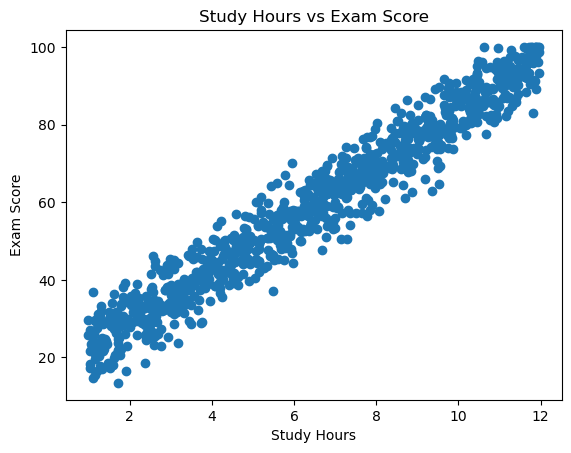

In [5]:
plt.scatter(df['StudyHours'], df['ExamScore'])

plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.title('Study Hours vs Exam Score')

plt.show()

**Q4.** Separate the dataset into an independent variable `X` and a dependent variable `y`.

In [6]:
x = df[["StudyHours"]]
y = df[["ExamScore"]]


**Q5.** Split the data into training and testing sets.

In [7]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y)

In [8]:
x_train

,StudyHours
607,7.09
235,7.59
930,1.79
315,6.50
722,7.66
...,...
682,8.78
332,3.44
655,2.95
724,6.55


In [9]:
y_train

,ExamScore
607,63.63
235,63.41
930,33.82
315,58.17
722,68.86
...,...
682,76.21
332,29.45
655,34.12
724,63.55


In [10]:
x_test

,StudyHours
286,6.80
21,11.65
728,7.31
524,7.55
362,10.91
...,...
789,9.72
791,4.93
234,6.39
379,3.08


In [11]:
y_test

,ExamScore
286,69.40
21,94.07
728,67.07
524,71.36
362,85.11
...,...
789,77.28
791,51.23
234,64.34
379,31.19


**Q6.** Build a Simple Linear Regression model and train it using the training data.

In [12]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression()
lin.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


**Q7.** Print the slope and intercept of the fitted regression line.

In [13]:
lin.coef_

array([[6.80871467]])

In [14]:
lin.intercept_

array([15.13689495])

**Q8.** Predict `ExamScore` values for the test set.

In [15]:
predicated_values = lin.predict(x_test)
predicated_values

array([[61.43615474],
       [94.4584209 ],
       [64.90859922],
       [66.54269074],
       [89.41997205],
       [51.01882129],
       [26.91597134],
       [22.14987107],
       [84.04108745],
       [87.44544479],
       [91.3944993 ],
       [49.5889912 ],
       [80.43246868],
       [36.38008474],
       [45.29950096],
       [78.18559283],
       [74.10036403],
       [78.11750569],
       [82.20273449],
       [82.40699593],
       [45.09523952],
       [54.01465574],
       [68.517218  ],
       [29.63945721],
       [93.16476512],
       [25.96275129],
       [64.56816349],
       [41.21427215],
       [38.42269914],
       [51.69969275],
       [74.50888691],
       [23.30735256],
       [74.16845118],
       [55.03596294],
       [89.21571061],
       [48.7038583 ],
       [75.6663684 ],
       [74.6450612 ],
       [63.47876914],
       [58.64458172],
       [32.90764025],
       [64.84051207],
       [87.64970623],
       [53.87848145],
       [75.6663684 ],
       [58

**Q9.** Calculate the model's training score and testing score.

In [16]:
lin.score(x_test,y_test)

0.9490097870520448

In [17]:
lin.score(x_train,y_train)

0.9474331713173567

**Q10.** Calculate the error between the actual and predicted values for the test set.

In [18]:
error = y_test - predicated_values
error

,ExamScore
286,7.963845
21,-0.388421
728,2.161401
524,4.817309
362,-4.309972
...,...
789,-4.037602
791,2.526142
234,5.695418
379,-4.917736


**Q11.** Plot the actual test values and the predicted values, along with the best fit line.

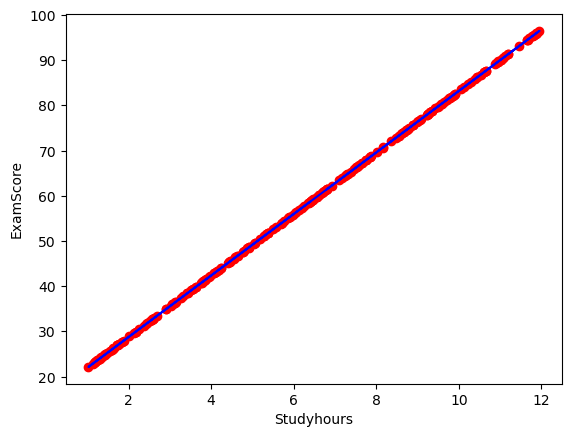

In [19]:
plt.xlabel("Studyhours")
plt.ylabel("ExamScore")
plt.scatter(x_test,predicated_values, color="red",marker="o")
plt.plot(x_test,predicated_values, color="blue")

## **Section 2: Multiple Linear Regression**

**Dataset:** `car_price_multiple.csv`
**Shape:** (5000, 4)
**Columns:** `EngineSize_L`, `Mileage_km`, `CarAge_years` (inputs), `Price_USD` (output)

**Q1.** Load `car_price_multiple.csv` into a DataFrame and display its structure (`.info()` and `.describe()`).

In [20]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [21]:
df = pd.read_csv("C:/Users/raajm/Downloads/car_price_multiple.csv")
df

,EngineSize_L,Mileage_km,CarAge_years,Price_USD
0,2.31,118374.0,0.7,27190.09
1,1.08,134437.0,3.9,15215.58
2,2.65,6908.0,12.9,22430.60
3,2.31,66733.0,12.7,19368.15
4,2.26,143137.0,4.2,22013.22
...,...,...,...,...
4995,1.31,153154.0,3.7,17945.60
4996,3.34,44333.0,3.8,29196.96
4997,2.98,146968.0,13.7,16567.93
4998,1.41,154746.0,6.1,15665.44


**Q2.** Confirm the dataset has no missing or duplicate values.

In [22]:
print(df.shape)
print(df.isnull().sum())

(5000, 4)
EngineSize_L    0
Mileage_km      0
CarAge_years    0
Price_USD       0
dtype: int64


**Q3.** Separate the independent variables `X` (`EngineSize_L`, `Mileage_km`, `CarAge_years`) and the dependent variable `y` (`Price_USD`).

In [23]:
x = df[['EngineSize_L','Mileage_km','CarAge_years']]
y = df[['Price_USD']]

In [24]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(3750, 3)
(1250, 3)
(3750, 1)
(1250, 1)


**Q4.** Split the dataset into training and testing sets using an 80-20 split.

In [25]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
x, y, test_size=0.2, random_state=42)

In [26]:
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x_train: (4000, 3)
x_test: (1000, 3)
y_train: (4000, 1)
y_test: (1000, 1)


**Q5.** Build and train a Multiple Linear Regression model on the training data.

In [27]:
from sklearn.linear_model import LinearRegression
Multi_lin = LinearRegression()
Multi_lin.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


**Q6.** Predict `Price_USD` for the test set.

In [28]:
x_test

,EngineSize_L,Mileage_km,CarAge_years
1501,1.34,138086.0,14.2
2586,3.72,162045.0,5.9
2653,3.44,30183.0,6.6
1055,3.52,101287.0,2.6
705,2.48,185176.0,5.6
...,...,...,...
4711,2.98,182512.0,11.4
2313,3.48,187019.0,10.0
3214,3.96,168890.0,7.7
2732,2.85,69746.0,3.1


**Q7.** Print the model's coefficients and intercept. Identify which feature has the strongest influence based on coefficient magnitude.

In [29]:
Multi_lin.coef_ 

array([[ 3.23117258e+03, -4.49990975e-02, -8.41692346e+02]])

In [30]:
Multi_lin.intercept_

array([24907.81041774])

**Q8.** Calculate the training score and testing score of the model.

In [58]:
Multi_lin.score(x_test,y_test)

0.9290167145655365

In [35]:
predicted_values = Multi_lin.predict(x_test)
predicted_values

array([[11071.80498329],
       [24669.9088146 ],
       [29109.66683977],
       [29535.31420507],
       [19874.88839939],
       [13595.07233377],
       [26857.87597053],
       [26535.0568312 ],
       [24309.90879167],
       [17190.50269093],
       [23959.22669748],
       [31957.60026584],
       [20248.14744968],
       [16458.75697957],
       [19902.40066138],
       [29267.84214467],
       [31571.62821516],
       [15087.32714341],
       [29222.34440835],
       [21097.55743473],
       [16838.64346918],
       [21945.33782909],
       [25147.20779556],
       [29594.85634256],
       [23352.10781467],
       [23106.76265653],
       [16846.05538044],
       [21106.23262048],
       [18280.23882488],
       [19086.3977456 ],
       [17189.76541128],
       [24637.52744326],
       [19954.4424281 ],
       [29477.0512083 ],
       [12730.87440046],
       [25151.74578436],
       [19387.80039077],
       [21755.74368752],
       [19537.93842887],
       [29087.4855906 ],


**Q9.** Compute MAE, MSE, RMSE, and R² score for the model's predictions.

In [36]:
from sklearn.metrics import *
MSE = mean_squared_error(y_test,predicted_values)
MAE = mean_absolute_error(y_test,predicted_values)
RMSE = (MSE) ** (1/2)
r_square = r2_score(y_test,predicted_values)

In [37]:
print(np.round(MSE,2))
print(np.round(MAE,2))
print(np.round(RMSE,2))
print(r_square)

2219821.17
1191.02
1489.91
0.9290167145655365


**Q10.** Create a scatter plot of Actual vs Predicted prices, with a diagonal reference line representing perfect predictions.

In [38]:
y_test.min()

Price_USD    6877.53
dtype: float64

In [39]:
y_test.max()

Price_USD    37579.6
dtype: float64

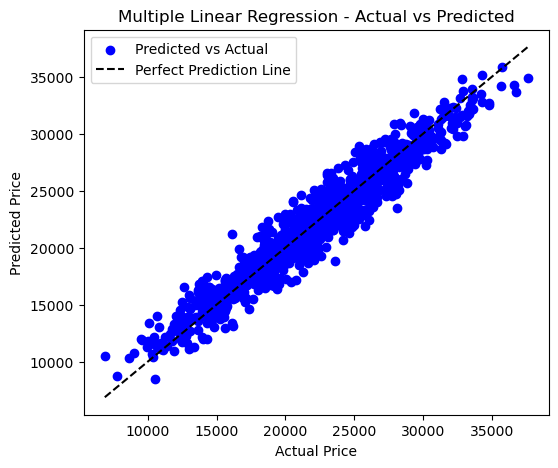

In [40]:
y_pred = Multi_lin.predict(x_test)

plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred,color='blue',label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
        color='black',linestyle='--', label='Perfect Prediction Line')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Multiple Linear Regression - Actual vs Predicted")
plt.legend()
plt.show()

## **Section 3: Gradient Boosting Regressor**

**Dataset:** `laptop_price_gbr.csv`
**Shape:** (10000, 6)
**Columns:** `RAM_GB`, `Storage_GB`, `ScreenSize_inch`, `Weight_kg`, `BatteryLife_hrs` (inputs), `Price_USD` (output)

**Q1.** Load `laptop_price_gbr.csv` into a DataFrame. Check its shape and data types.

In [62]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
df = pd.read_csv("C:/Users/raajm/Downloads/laptop_price_gbr.csv")
df

,RAM_GB,Storage_GB,ScreenSize_inch,Weight_kg,BatteryLife_hrs,Price_USD
0,16,2048,13.0,1.17,16.0,1365.85
1,4,256,12.6,2.44,7.5,371.03
2,8,1024,16.0,1.60,13.5,686.07
3,32,1024,14.1,2.68,10.8,1164.84
4,4,1024,15.2,1.37,9.7,622.77
...,...,...,...,...,...,...
9995,4,256,17.2,1.20,8.7,323.50
9996,4,2048,11.6,1.62,5.9,1022.11
9997,16,1024,13.1,1.78,15.5,955.66
9998,32,1024,13.8,0.96,4.5,1144.20


**Q2.** Confirm the dataset has no missing values.

In [50]:
print(df.shape)
print(df.isnull().sum())

(10000, 6)
RAM_GB             0
Storage_GB         0
ScreenSize_inch    0
Weight_kg          0
BatteryLife_hrs    0
Price_USD          0
dtype: int64


**Q3.** Separate the independent variables `X` and the dependent variable `y` (`Price_USD`).

In [51]:
x = df[['RAM_GB','Storage_GB','ScreenSize_inch','Weight_kg','BatteryLife_hrs']]
y = df['Price_USD']

**Q4.** Split the dataset into training and testing sets (80-20 split, `random_state=42`).

In [52]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

**Q5.** Build a `GradientBoostingRegressor` model with `n_estimators=100`, `learning_rate=0.1`, and `max_depth=3`. Train it on the training data.

In [54]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

**Q6.** Predict `Price_USD` for the test set.

In [55]:
gbr.fit(x_train,y_train)
y_pred = gbr.predict(x_test)

**Q7.** Evaluate the model using MAE, MSE, RMSE, and R² score.

In [56]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np

mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

print("MAE:",round(mae,2))
print("RMSE:",round(rmse,2))
print("R squared score:",round(r2,4))

MAE: 48.85
RMSE: 61.03
R squared score: 0.9842


**Q8.** Create a scatter plot comparing Actual vs Predicted prices, with a diagonal reference line for perfect predictions.

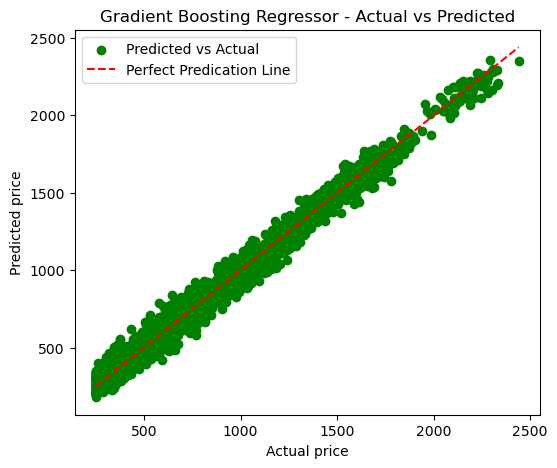

In [57]:
plt.figure(figsize=(6,5))
plt.scatter(y_test,y_pred,color='green',label='Predicted vs Actual')
plt.plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],
        color ='red',linestyle='--',label='Perfect Predication Line')
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Gradient Boosting Regressor - Actual vs Predicted")
plt.legend()
plt.show()

**Q9.** Extract and plot the feature importances from the trained model. Which feature contributes most to predicting `Price_USD`?

In [60]:
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': gbr.feature_importances_
})

print(feature_importance.sort_values(
    by='Importance', ascending=False
))

           Feature  Importance
0           RAM_GB    0.686909
1       Storage_GB    0.276293
3        Weight_kg    0.014767
4  BatteryLife_hrs    0.013139
2  ScreenSize_inch    0.008891


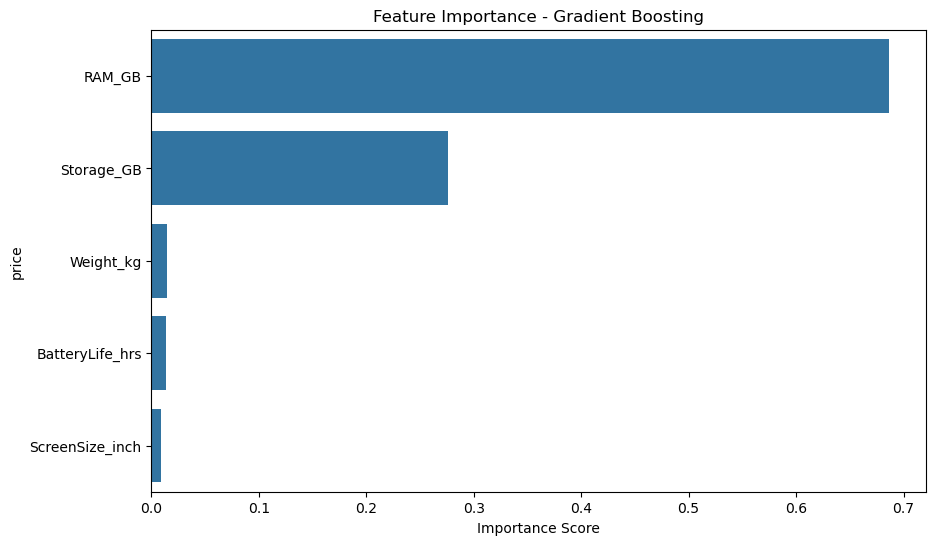

In [65]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.sort_values(
        by='Importance', ascending=False
    ),
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Gradient Boosting')
plt.xlabel('Importance Score')
plt.ylabel('price')
plt.show()

**Q10.** Compare the R² score of this model with the Multiple Linear Regression model from Section 2 (conceptually) — which type of model would you expect to perform better on non-linear relationships, and why?

In [66]:
from sklearn.metrics import r2_score

gb_r2 = r2_score(y_test, y_pred)

print("Gradient Boosting R2 Score:", gb_r2)

Gradient Boosting R2 Score: 0.9842494014600353


In [68]:
mlr_r2 = r2_score(y_test, y_pred)

print("Multiple Linear Regression R2 Score:", mlr_r2)

Multiple Linear Regression R2 Score: 0.9842494014600353
